# CellVOCAL analysis of embryonic mouse lung

This tutorial models a prepared Stereo-seq embryonic lung H5AD. Spatial pseudotime provides weak temporal orientation, while CellVOCAL learns transcriptomic velocity and communication influence from RNA state and local tissue structure.

> Start Jupyter from the repository root. Training is commented by default.

## Model specification

The selected configuration uses 16 spatial neighbors, a low learning rate, and a strong temporal-ordering weight. Cell annotations are retained for interpretation but are not supplied as model features.

In [1]:
from base64 import b64encode
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "model").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import anndata as ad
import numpy as np
import pandas as pd
import torch
from IPython.display import HTML, display
from IPython.utils.capture import capture_output

from model.train.config import CellVOCALConfig
from pipeline.analysis import CellVOCALAnalysis
from pipeline.cellvocal import run_cellvocal
from utils.tools.real_time_prior import set_real_time_prior


In [2]:
DATA_ROOT = ROOT / "paper" / "data" / "mouse_lung"

cfg = CellVOCALConfig()
cfg.train.device = "cuda:0" if torch.cuda.is_available() else "cpu"
cfg.train.checkpoint_dir = DATA_ROOT / "cellvocal" / "checkpoints"
cfg.eval.output_dir = DATA_ROOT / "cellvocal" / "results"
cfg.model.use_cell_annotation = False
cfg.graph.n_spatial_neighbors = 16
cfg.train.time_prior_source = "obs"
cfg.train.time_prior_obs_key = "tprior"
cfg.train.velocity_order_min_delta = 1e-4
cfg.train.lr = 5e-6
cfg.train.w_time = 0.8

## Train CellVOCAL

The prepared H5AD is loaded directly. The existing coordinates are assigned to the standard key, and the shared utility derives the spatial time prior used by the model.

In [3]:
# adata = ad.read_h5ad(DATA_ROOT / "raw" / "stereo-seq-e14-lung_pp.h5ad")
# adata.obsm["spatial"] = np.asarray(adata.obsm["X_spatial"], dtype=float)
# set_real_time_prior(adata, "mouse_lung")
# result = run_cellvocal(adata, config=cfg)

## Evaluate the epithelial-to-mesenchymal axis

For the embryonic mouse lung, the interpretable contrast is between epithelial and mesenchymal compartments. The table reports abundance, the spatial prior, and fitted median time before the global direction metrics and spatial maps.

,spots,spots (%),prior_median,inferred_time_median
clusters,,,,
Epithelial,330,32.039,8.222,0.464
Mesenchymal,700,67.961,16.015,0.512


,Dataset,Mouse lung
Metrics,Model,
Time Correlation,CellVOCAL,0.912
Spatial Velocity Consistency,CellVOCAL,0.997
Spatial Time Consistency,CellVOCAL,0.827
CBDir,CellVOCAL,0.125



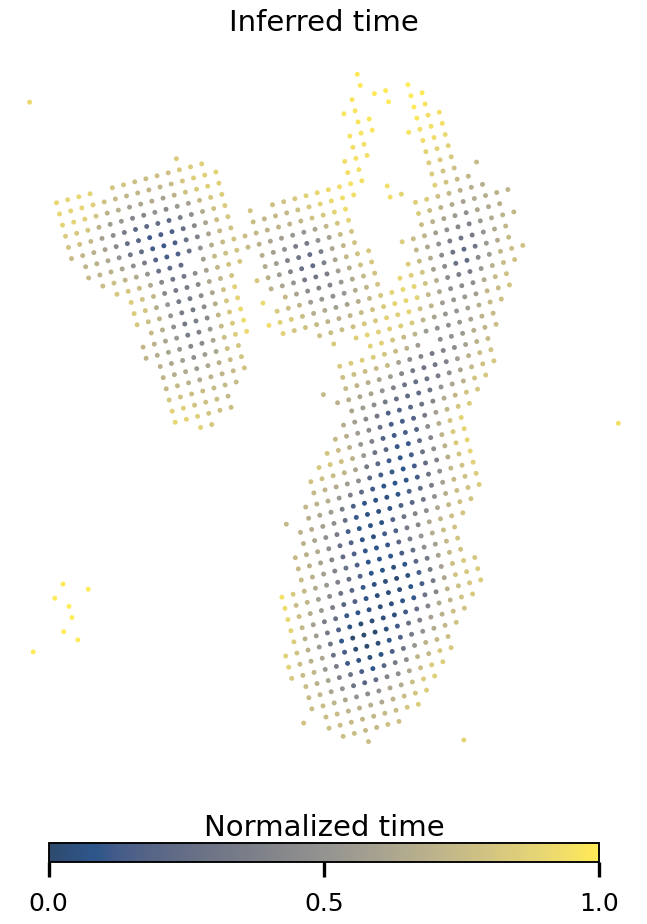
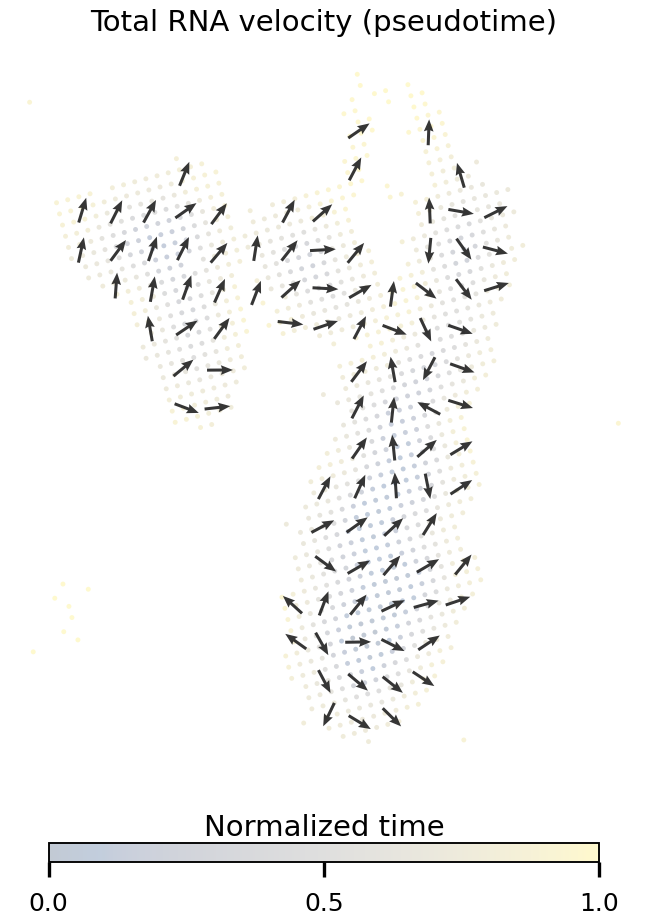
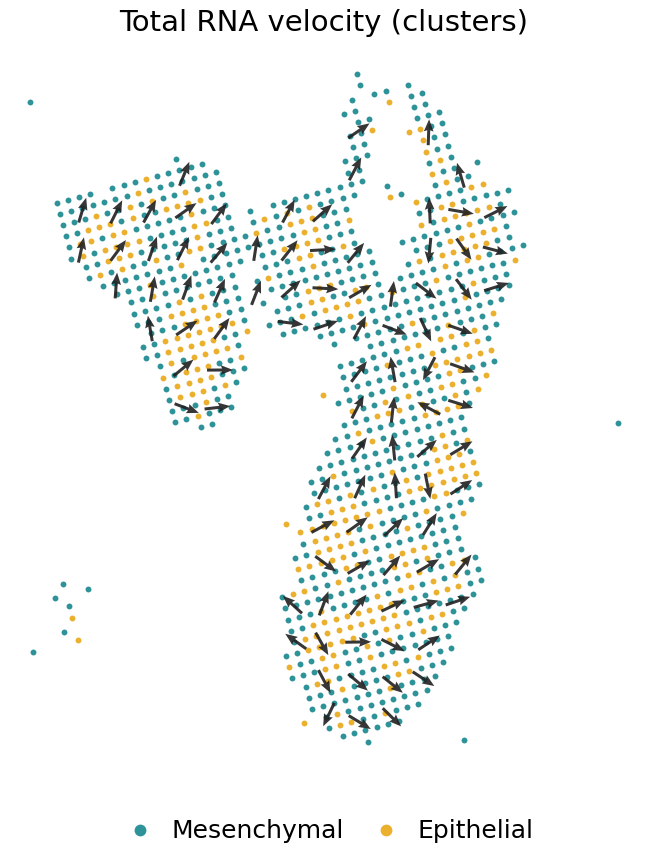

In [4]:
analysis = CellVOCALAnalysis.from_h5ad(cfg.eval.output_dir / "out.h5ad", config=cfg)
compartment_summary = analysis.adata.obs.groupby("clusters", observed=True).agg(
    spots=("cv_time", "size"), prior_median=("tprior", "median"), inferred_time_median=("cv_time", "median")
)
compartment_summary["spots (%)"] = 100 * compartment_summary["spots"] / compartment_summary["spots"].sum()
display(compartment_summary[["spots", "spots (%)", "prior_median", "inferred_time_median"]].round(3))

with capture_output():
    set_real_time_prior(analysis.adata, "mouse_lung")
    metrics = analysis.evaluate_metrics(cluster_edges=[("Epithelial", "Mesenchymal")], dataset_name="Mouse lung", n_jobs=cfg.eval.benchmark_n_jobs)
display(metrics)
with capture_output():
    velocity_plots = analysis.plot_velocity(output_dir=DATA_ROOT / "cellvocal" / "velocity")
image_tiles = []
for path in velocity_plots:
    encoded = b64encode(Path(path).read_bytes()).decode("ascii")
    image_tiles.append(f'<img src="data:image/png;base64,{encoded}" alt="{Path(path).stem}" style="flex:1 1 0;min-width:0;width:32%;height:auto;object-fit:contain">')
display(HTML('<div style="display:flex;flex-wrap:nowrap;gap:8px;align-items:flex-start;width:100%">' + "".join(image_tiles) + "</div>"))